# Kumasi Monthly Rent Predictor (Ghana)
Predicts the **monthly rent in GHS** of a rental home in Kumasi from its neighbourhood, type, size, amenities and distance to KNUST / Kejetia.



## 1. Setup and load data

In [5]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

df = pd.read_csv("Kumasi_Rent.csv")
df.head()

,neighbourhood,property_type,bedrooms,bathrooms,shared_bathroom,floor_area_sqm,furnishing,water_source,prepaid_meter,road_type,gated_compound,air_conditioning,parking,wifi_ready,building_age_years,dist_to_knust_km,dist_to_kejetia_km,monthly_rent_ghs
0,Ejisu,Self-Contained,1,1,No,30.0,Semi-furnished,Ghana Water,No,Untarred,No,Yes,No,No,NaN,11.7,14.3,770.0
1,Oforikrom,Single Room,1,0,Yes,NaN,Semi-furnished,Ghana Water,No,Untarred,No,No,No,Yes,9.0,4.8,6.3,270.0
2,Ayeduase,Self-Contained,1,1,No,20.7,Unfurnished,Ghana Water,Yes,Untarred,No,No,No,Yes,4.0,1.1,9.1,1210.0
3,Santasi,Chamber and Hall,2,0,Yes,25.1,Semi-furnished,Borehole,Yes,Tarred,No,No,No,No,13.0,8.8,5.1,830.0
4,Oforikrom,Chamber and Hall,2,0,Yes,25.5,Unfurnished,Ghana Water,No,Tarred,Yes,No,No,No,5.0,3.9,6.3,560.0


In [6]:
df.shape

(1500, 18)

In [8]:
 df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   neighbourhood       1500 non-null   str    
 1   property_type       1500 non-null   str    
 2   bedrooms            1500 non-null   int64  
 3   bathrooms           1500 non-null   int64  
 4   shared_bathroom     1500 non-null   str    
 5   floor_area_sqm      1455 non-null   float64
 6   furnishing          1500 non-null   str    
 7   water_source        1500 non-null   str    
 8   prepaid_meter       1500 non-null   str    
 9   road_type           1500 non-null   str    
 10  gated_compound      1500 non-null   str    
 11  air_conditioning    1500 non-null   str    
 12  parking             1500 non-null   str    
 13  wifi_ready          1500 non-null   str    
 14  building_age_years  1440 non-null   float64
 15  dist_to_knust_km    1500 non-null   float64
 16  dist_to_kejetia_k

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
bedrooms,1500.0,1.865333,1.175352,1.0,1.00,2.0,2.0,6.0
bathrooms,1500.0,1.294667,1.223998,0.0,0.75,1.0,2.0,7.0
floor_area_sqm,1455.0,63.086873,62.580409,10.0,24.90,37.9,79.4,318.9
building_age_years,1440.0,8.304167,5.529426,0.0,4.00,7.0,11.0,37.0
dist_to_knust_km,1500.0,6.249667,3.125544,0.3,3.20,7.3,8.7,12.5
dist_to_kejetia_km,1500.0,6.058067,2.810287,0.7,3.80,5.7,7.7,15.4
monthly_rent_ghs,1500.0,3233.640000,4266.693208,130.0,740.00,1665.0,3762.5,48310.0


## 2. Data quality checks

In [5]:
print("Duplicate rows:", df.duplicated().sum())
df.isna().sum()[df.isna().sum() > 0]

Duplicate rows: 0


floor_area_sqm        45
building_age_years    60
dtype: int64

A few missing values in `floor_area_sqm` and `building_age_years`; the pipeline below fills them with the median instead of dropping rows.

## 3. Exploratory data analysis

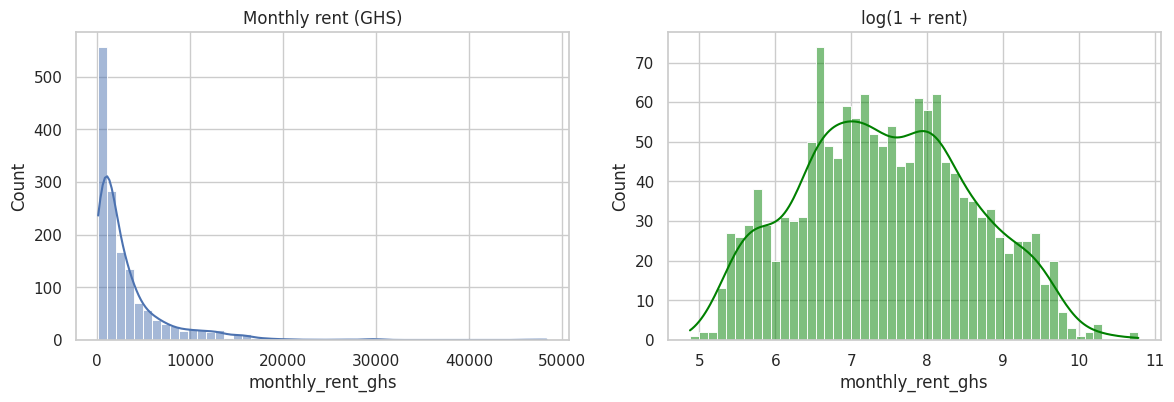

count     1500.000000
mean      3233.640000
std       4266.693208
min        130.000000
25%        740.000000
50%       1665.000000
75%       3762.500000
90%       8221.000000
99%      17767.400000
max      48310.000000
Name: monthly_rent_ghs, dtype: float64


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df.monthly_rent_ghs, bins=50, ax=ax[0], kde=True); ax[0].set_title("Monthly rent (GHS)")
sns.histplot(np.log1p(df.monthly_rent_ghs), bins=50, ax=ax[1], kde=True, color="green"); ax[1].set_title("log(1 + rent)")
plt.show()
print(df.monthly_rent_ghs.describe(percentiles=[.25,.5,.75,.9,.99]))

Rent is strongly **right-skewed** (a few large houses cost 10–40× a single room). Log-transforming the target makes it near-symmetric, so we model `log(rent)` and convert back to cedis.

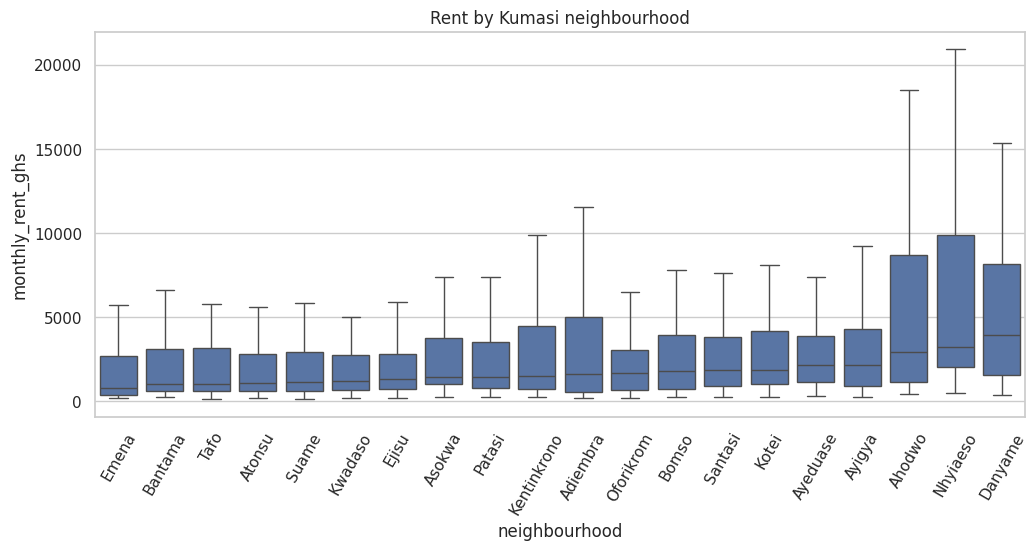

In [7]:
order = df.groupby("neighbourhood").monthly_rent_ghs.median().sort_values().index
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="neighbourhood", y="monthly_rent_ghs", order=order, showfliers=False)
plt.xticks(rotation=60); plt.title("Rent by Kumasi neighbourhood"); plt.show()

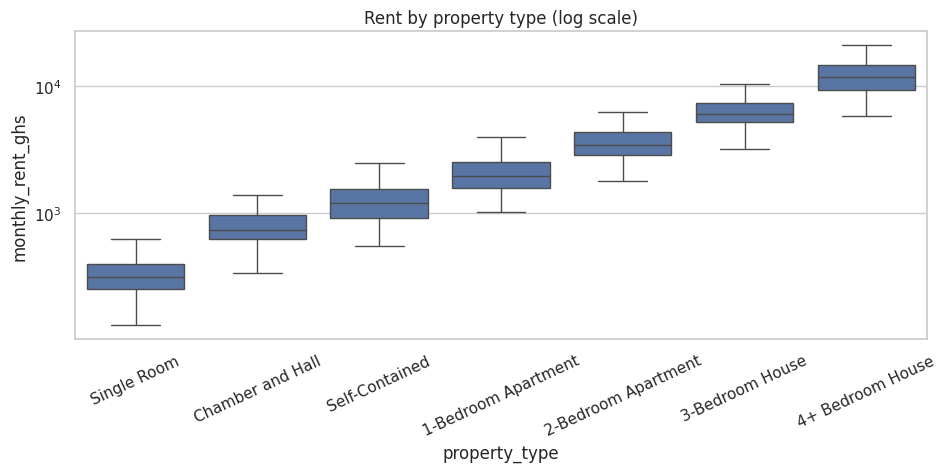

In [8]:
order = df.groupby("property_type").monthly_rent_ghs.median().sort_values().index
plt.figure(figsize=(11, 4))
sns.boxplot(data=df, x="property_type", y="monthly_rent_ghs", order=order, showfliers=False)
plt.xticks(rotation=25); plt.yscale("log"); plt.title("Rent by property type (log scale)"); plt.show()

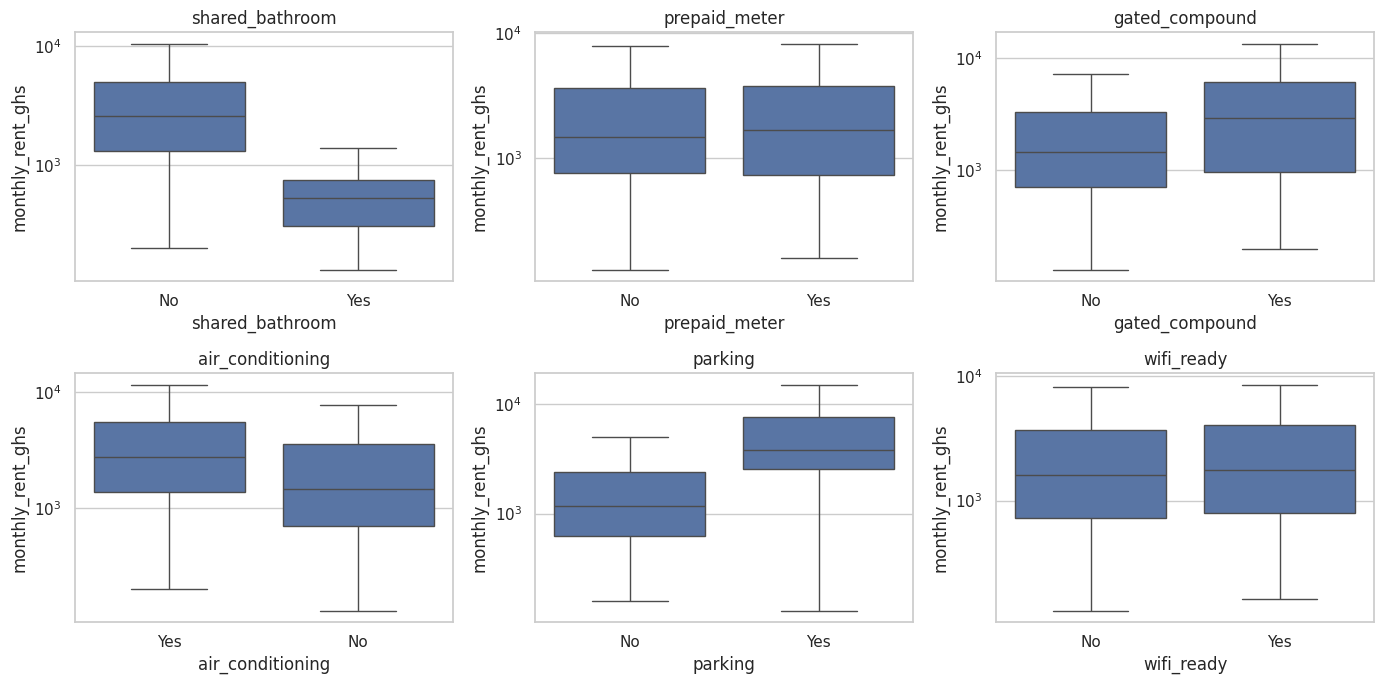

In [9]:
binary = ["shared_bathroom","prepaid_meter","gated_compound","air_conditioning","parking","wifi_ready"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(axes.ravel(), binary):
    sns.boxplot(data=df, x=c, y="monthly_rent_ghs", ax=a, showfliers=False); a.set_yscale("log"); a.set_title(c)
plt.tight_layout(); plt.show()

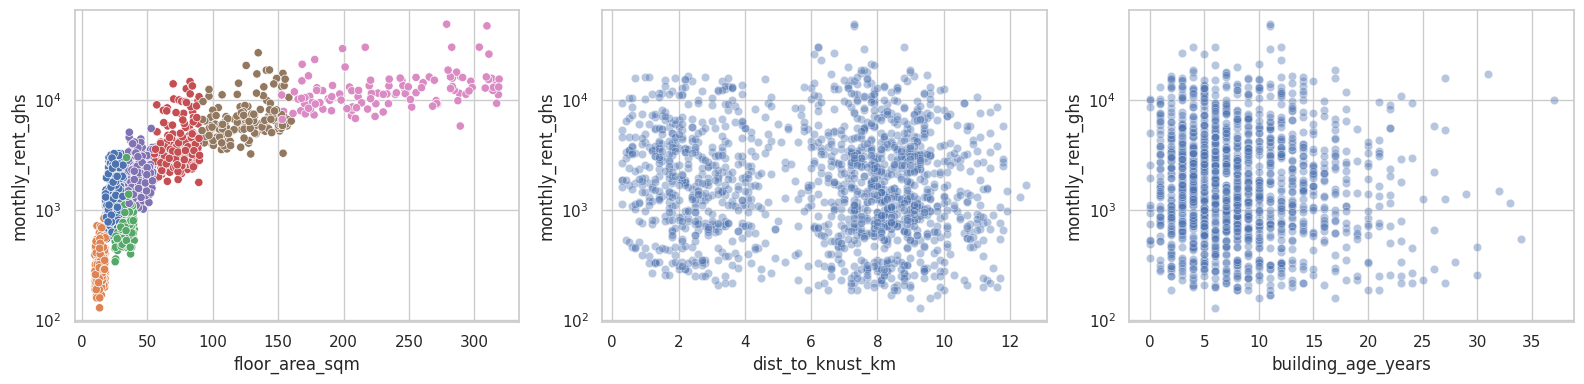

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df, x="floor_area_sqm", y="monthly_rent_ghs", hue="property_type", ax=ax[0], legend=False); ax[0].set_yscale("log")
sns.scatterplot(data=df, x="dist_to_knust_km", y="monthly_rent_ghs", ax=ax[1], alpha=.4); ax[1].set_yscale("log")
sns.scatterplot(data=df, x="building_age_years", y="monthly_rent_ghs", ax=ax[2], alpha=.4); ax[2].set_yscale("log")
plt.tight_layout(); plt.show()

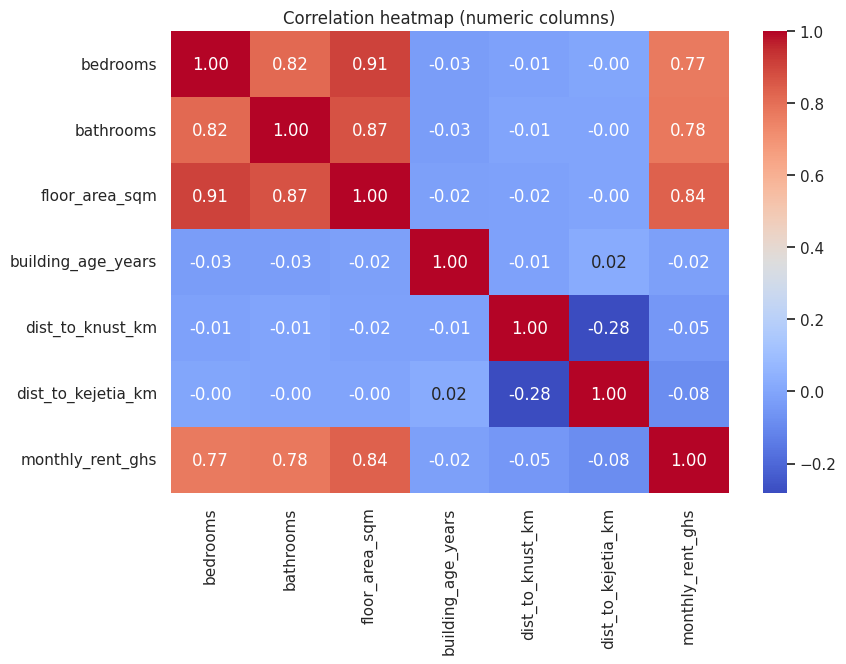

In [11]:
num_cols_all = df.select_dtypes("number").columns
plt.figure(figsize=(9, 6))
sns.heatmap(df[num_cols_all].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap (numeric columns)"); plt.show()

## 4. Train / test split and preprocessing pipeline

In [12]:
from sklearn.model_selection import train_test_split

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

class HybridResidualRegressor(BaseEstimator, RegressorMixin):
    # Ridge captures the broad additive price structure; gradient boosting then learns
    # what Ridge missed (interactions such as 'furnishing matters more near KNUST').
    def __init__(self, alpha=1.0, n_estimators=300, learning_rate=0.05, max_depth=3,
                 subsample=0.8, min_samples_leaf=3, random_state=0):
        self.alpha = alpha; self.n_estimators = n_estimators; self.learning_rate = learning_rate
        self.max_depth = max_depth; self.subsample = subsample
        self.min_samples_leaf = min_samples_leaf; self.random_state = random_state

    def fit(self, X, y):
        self.linear_ = Ridge(alpha=self.alpha).fit(X, y)
        resid = y - self.linear_.predict(X)
        self.boost_ = GradientBoostingRegressor(
            n_estimators=self.n_estimators, learning_rate=self.learning_rate, max_depth=self.max_depth,
            subsample=self.subsample, min_samples_leaf=self.min_samples_leaf,
            random_state=self.random_state).fit(X, resid)
        return self

    def predict(self, X):
        return self.linear_.predict(X) + self.boost_.predict(X)

def make_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])

def make_pipeline(model, preprocessor):
    # Preprocess -> model, trained on log(rent) and returning rent in GHS.
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", preprocessor), ("model", model)]),
        func=np.log1p, inverse_func=np.expm1)

TARGET = "monthly_rent_ghs"
X = df.drop(columns=TARGET)
y = df[TARGET]

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric    :", num_cols)
print("Categorical:", cat_cols)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
preprocess = make_preprocessor(num_cols, cat_cols)   # impute + scale numerics, one-hot categoricals

Numeric    : ['bedrooms', 'bathrooms', 'floor_area_sqm', 'building_age_years', 'dist_to_knust_km', 'dist_to_kejetia_km']
Categorical: ['neighbourhood', 'property_type', 'shared_bathroom', 'furnishing', 'water_source', 'prepaid_meter', 'road_type', 'gated_compound', 'air_conditioning', 'parking', 'wifi_ready']


## 5. Compare models (5-fold cross-validation)
Every model is wrapped in `TransformedTargetRegressor` so it learns `log(rent)` but reports errors in **GHS**.

In [13]:
from sklearn.linear_model import Ridge, RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.model_selection import cross_validate, KFold

make = lambda model: make_pipeline(model, preprocess)

candidates = {
    "Ridge (linear baseline)": make(Ridge(alpha=1.0)),
    "Random Forest":           make(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)),
    "Gradient Boosting":       make(GradientBoostingRegressor(n_estimators=800, learning_rate=0.03, max_depth=3, subsample=0.8, random_state=0)),
    "Stacking (Ridge+GB)":     make(StackingRegressor(
                                    [("ridge", Ridge(1.0)),
                                     ("gb", GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=0))],
                                    final_estimator=RidgeCV(), cv=5)),
    "Hybrid (Ridge + boosted residuals)": make(HybridResidualRegressor()),
}
cv = KFold(5, shuffle=True, random_state=42)
rows = []
for name, m in candidates.items():
    s = cross_validate(m, X_train, y_train, cv=cv, n_jobs=-1,
                       scoring=["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"])
    rows.append({"model": name, "R2": s["test_r2"].mean(),
                 "MAE (GHS)": -s["test_neg_mean_absolute_error"].mean(),
                 "RMSE (GHS)": -s["test_neg_root_mean_squared_error"].mean()})
results = pd.DataFrame(rows).set_index("model").round(3).sort_values("MAE (GHS)")
results

,R2,MAE (GHS),RMSE (GHS)
model,,,
Hybrid (Ridge + boosted residuals),0.975,312.564,645.100
Stacking (Ridge+GB),0.966,350.310,770.550
Ridge (linear baseline),0.956,390.420,871.014
Gradient Boosting,0.946,398.114,967.275
Random Forest,0.862,600.523,1554.195


Rent is mostly *additive on the log scale*, which is why a plain linear model is a strong baseline and pure tree ensembles lag behind. The **hybrid** keeps the linear backbone and lets boosted trees learn the leftover interactions (e.g. furnishing and gated compounds matter more in upmarket suburbs; campus premium decays sharply with distance to KNUST). It should come out on top.

## 6. Tune the hybrid (randomised search)

In [14]:
from sklearn.model_selection import RandomizedSearchCV

hybrid = make(HybridResidualRegressor())
param_dist = {
    "regressor__model__alpha":          [0.3, 1.0, 3.0],
    "regressor__model__n_estimators":   [200, 300, 500],
    "regressor__model__learning_rate":  [0.03, 0.05, 0.08],
    "regressor__model__max_depth":      [2, 3, 4],
    "regressor__model__subsample":      [0.7, 0.8, 1.0],
    "regressor__model__min_samples_leaf": [3, 5, 10],
}
search = RandomizedSearchCV(hybrid, param_dist, n_iter=20, cv=cv, scoring="neg_mean_absolute_error",
                            random_state=42, n_jobs=-1)
search.fit(X_train, y_train)
print("Best params:", {k.split("__")[-1]: v for k, v in search.best_params_.items()})
print("CV MAE (GHS):", round(-search.best_score_, 1))
best = search.best_estimator_

Best params: {'subsample': 0.7, 'n_estimators': 500, 'min_samples_leaf': 3, 'max_depth': 3, 'learning_rate': 0.03, 'alpha': 0.3}
CV MAE (GHS): 310.0


## 7. Evaluate on the held-out test set

In [15]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

pred = best.predict(X_test)
r2   = r2_score(y_test, pred)
mae  = mean_absolute_error(y_test, pred)
rmse = mean_squared_error(y_test, pred) ** 0.5
mape = (np.abs(pred - y_test) / y_test).mean() * 100
print(f"R²   : {r2:.3f}\nMAE  : GHS {mae:,.0f}\nRMSE : GHS {rmse:,.0f}\nMAPE : {mape:.1f}%")

R²   : 0.978
MAE  : GHS 314
RMSE : GHS 668
MAPE : 10.2%


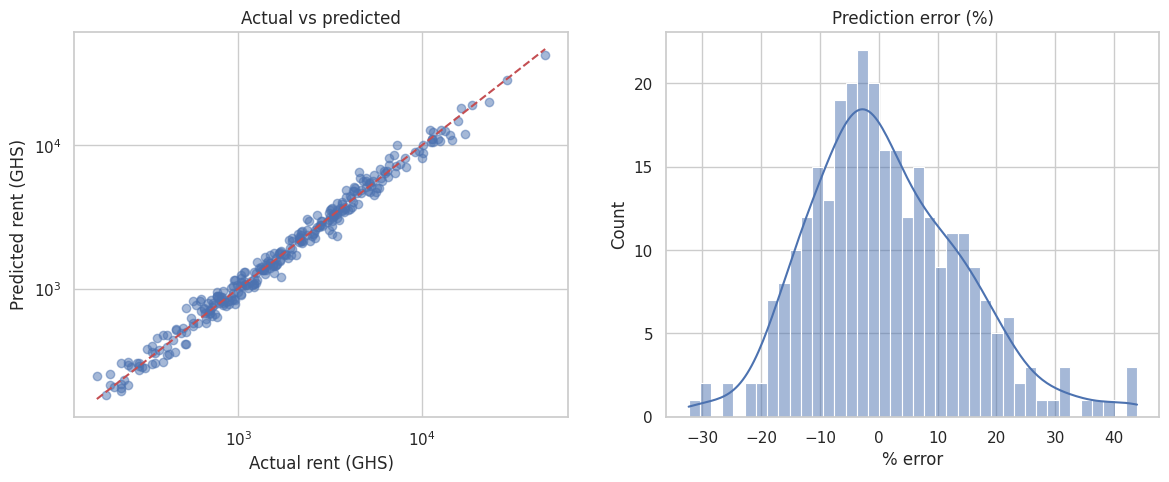

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(y_test, pred, alpha=.5); lim = [y_test.min(), y_test.max()]
ax[0].plot(lim, lim, "r--"); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Actual rent (GHS)"); ax[0].set_ylabel("Predicted rent (GHS)"); ax[0].set_title("Actual vs predicted")
resid_pct = (pred - y_test) / y_test * 100
sns.histplot(resid_pct, bins=40, ax=ax[1], kde=True); ax[1].set_title("Prediction error (%)"); ax[1].set_xlabel("% error")
plt.show()

In [17]:
err = X_test.assign(actual=y_test, predicted=pred.round(0))
err["abs_pct_err"] = (err.predicted - err.actual).abs() / err.actual * 100
err.groupby("property_type").abs_pct_err.mean().sort_values().round(1).rename("mean abs % error")

property_type
1-Bedroom Apartment     8.5
Self-Contained          9.4
2-Bedroom Apartment     9.6
4+ Bedroom House        9.8
3-Bedroom House        10.3
Chamber and Hall       11.8
Single Room            12.5
Name: mean abs % error, dtype: float64

## 8. What drives Kumasi rent? (permutation importance)

In [9]:
from sklearn.inspection import permutation_importance
# permutation importance measured on the original-input columns (works through the whole pipeline)
inner = best.regressor_
Xt = X_test
imp = permutation_importance(inner, Xt, np.log1p(y_test), n_repeats=10, random_state=42, n_jobs=-1,
                             scoring="r2")
imp_df = pd.Series(imp.importances_mean, index=X.columns).sort_values()
imp_df.plot(kind="barh", figsize=(8, 6), title="Permutation importance (drop in R² on log-rent)")
plt.show()

NameError: name 'best' is not defined

## 9. Predict for a new listing

In [19]:
def predict_rent(**listing):
    """Predict monthly rent (GHS). Missing numeric fields are imputed automatically."""
    row = pd.DataFrame([listing]).reindex(columns=X.columns)
    return float(best.predict(row)[0])

example = dict(neighbourhood="Ayeduase", property_type="Self-Contained", bedrooms=1, bathrooms=1,
               shared_bathroom="No", floor_area_sqm=26, furnishing="Furnished", water_source="Borehole",
               prepaid_meter="Yes", road_type="Tarred", gated_compound="No", air_conditioning="No",
               parking="No", wifi_ready="Yes", building_age_years=4, dist_to_knust_km=0.8, dist_to_kejetia_km=9.0)
print(f"Estimated rent: GHS {predict_rent(**example):,.0f} / month")

Estimated rent: GHS 2,229 / month


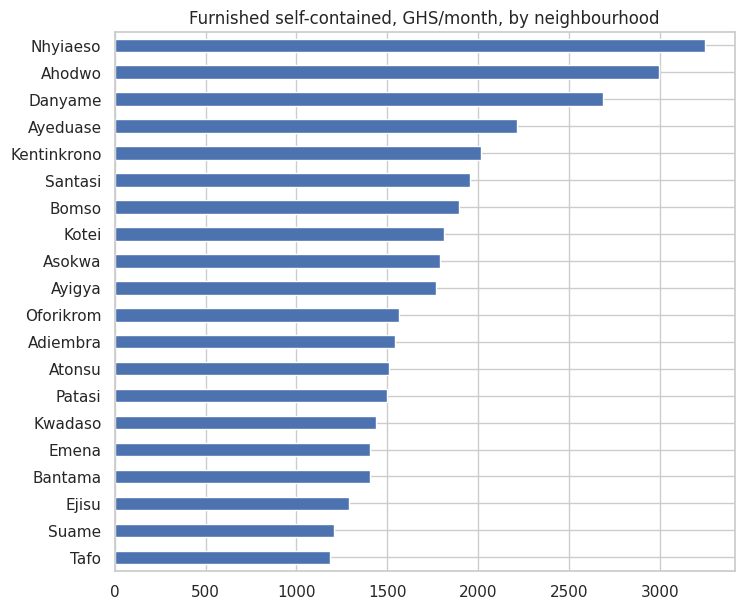

In [20]:
# What-if: same self-contained room in different neighbourhoods
hoods = df.groupby("neighbourhood")[["dist_to_knust_km", "dist_to_kejetia_km"]].median()
rows = []
for h, d in hoods.iterrows():
    r = {**example, "neighbourhood": h, "dist_to_knust_km": d.dist_to_knust_km, "dist_to_kejetia_km": d.dist_to_kejetia_km}
    rows.append((h, best.predict(pd.DataFrame([r]).reindex(columns=X.columns))[0]))
whatif = pd.Series(dict(rows)).sort_values()
whatif.round(0).plot(kind="barh", figsize=(8, 7), title="Furnished self-contained, GHS/month, by neighbourhood")
plt.show()

## 10. Summary
* Data: 1,500 synthetic Kumasi rental listings across 20 neighbourhoods and 7 property types.
* Model: a hybrid (Ridge + boosted residuals) trained on log-rent inside a preprocessing `Pipeline`, tuned with cross-validation. It beat Ridge, Random Forest, Gradient Boosting and stacking in CV.
* Use `predict_rent(...)` in section 9 to price any new listing.
* To use real data, keep the same columns and re-run the notebook.